# Task 5 – Netflix Content Release Trend Forecasting

**Goal:** use historical data to forecast how much content Netflix will add in the coming months. This is *time series forecasting*.

**What I'm forecasting:** the number of titles added to Netflix per month (from `date_added`). I compare a naive baseline with two classic forecasting models and keep whichever predicts best on data it hasn't seen.

In [ ]:
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

## Step 0 – Load and clean the data

Before any modelling I load the file and tidy it. What I do, and why:

- **Remove exact duplicate rows** (there are none in this file, but it is a good habit).
- **Parse `date_added`.** In this dataset dates look like `9/25/2021`, so I tell pandas the exact format.
- **Missing values** are not blank here. The file writes `Not Given` for unknown directors and countries, and I keep that in mind (for example `has_director` is 0 when the director is `Not Given`).
- **Turn `duration` into a number.** `"90 min"` becomes 90 and `"2 Seasons"` becomes 2.
- **Simplify genre names.** Netflix names the same genre differently for movies and shows (`Dramas` vs `TV Dramas`, `International Movies` vs `International TV Shows`). I merge them so a genre means the same thing for both types.

In [ ]:
DATA_PATH = "Dataset.csv"      # change this if the file is in another folder

df = pd.read_csv(DATA_PATH).drop_duplicates().reset_index(drop=True)
print("Dataset shape:", df.shape)

# Dates (format in this file is month/day/year)
df["date_added"] = pd.to_datetime(df["date_added"].str.strip(), format="%m/%d/%Y", errors="coerce")
df["year_added"] = df["date_added"].dt.year
df["month_added"] = df["date_added"].dt.month

# Duration as a number: "90 min" -> 90, "2 Seasons" -> 2
df["duration_num"] = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

# Helpers for comma separated columns
def split_items(text):
    return [p.strip() for p in str(text).split(",") if p.strip()]

def simplify_genre(name):
    """'TV Dramas' and 'Dramas' -> 'Dramas';  'International Movies' -> 'International'."""
    name = name.strip()
    if name in ("Movies", "TV Shows"):
        return "Other"
    name = re.sub(r"^TV\s+", "", name)
    name = re.sub(r"\s+(Movies|TV Shows|TV)$", "", name)
    return name

# Handy columns used by several tasks
df["genre_list"] = df["listed_in"].apply(lambda s: [simplify_genre(g) for g in split_items(s)])
df["n_genres"] = df["genre_list"].apply(len)
df["country_main"] = df["country"].apply(lambda s: split_items(s)[0] if split_items(s) else "Not Given")
df["has_director"] = (df["director"].str.strip() != "Not Given").astype(int)
df["years_to_add"] = (df["year_added"] - df["release_year"]).clip(lower=0)

# 0/1 columns for the 30 most common (simplified) genres, most common first
top_genres = pd.Series([g for lst in df["genre_list"] for g in lst]).value_counts().head(30).index.tolist()
genre_cols = []
for g in top_genres:
    col = "genre_" + g
    df[col] = df["genre_list"].apply(lambda lst, g=g: int(g in lst))
    genre_cols.append(col)

print(df["type"].value_counts().to_dict(), "| date range:", df["date_added"].min().date(), "to", df["date_added"].max().date())
df.head(3)

Dataset shape: (8790, 10)


{'Movie': 6126, 'TV Show': 2664} | date range: 2008-01-01 to 2021-09-25


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,...,genre_Spanish-Language,genre_Korean,genre_Classic,genre_LGBTQ,genre_Mysteries,genre_Science & Nature,genre_Anime Features,genre_Cult,genre_Other,genre_Teen
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,...,0,0,0,0,0,0,0,0,0,0
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",...,0,0,0,0,0,0,0,0,0,0
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",...,0,0,0,0,1,0,0,0,0,0


## Step 1 – Prepare time-based features

I count titles per month. Two cleaning decisions:
- **Start in January 2015.** Before that Netflix added only a handful of titles a year, which would distort the pattern.
- **Drop the last month.** The data ends on 25 September 2021, so September 2021 is incomplete and would look like a fake drop.

In [ ]:
monthly = df.set_index("date_added").resample("MS").size()
print("Last date in the data:", df["date_added"].max().date())

ts = monthly[monthly.index >= "2015-01-01"].iloc[:-1]
ts.index.freq = "MS"
print(f"Using {len(ts)} months: {ts.index.min().date()} to {ts.index.max().date()}")
ts.tail(8)

Last date in the data: 2021-09-25
Using 80 months: 2015-01-01 to 2021-08-01


date_added
2021-01-01    132
2021-02-01    109
2021-03-01    112
2021-04-01    188
2021-05-01    132
2021-06-01    207
2021-07-01    257
2021-08-01    178
Freq: MS, dtype: int64

## Step 2 – Analyze historical release patterns

Two views: the monthly line with a yearly bar chart, and a **seasonal decomposition** that splits the series into a long-term *trend*, a repeating *seasonal* pattern and leftover *noise*.

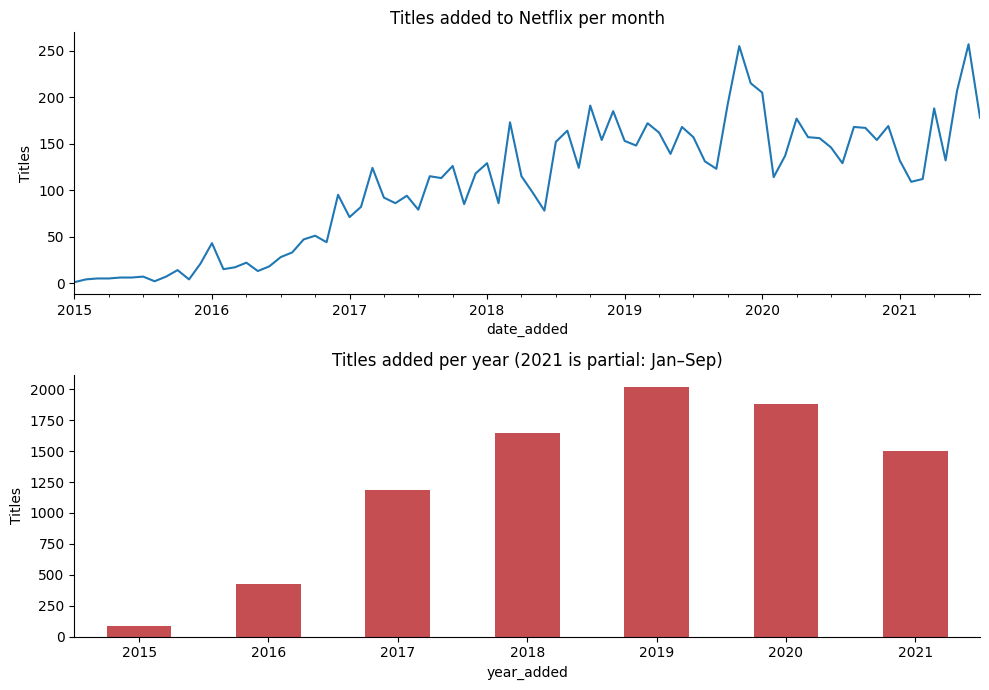

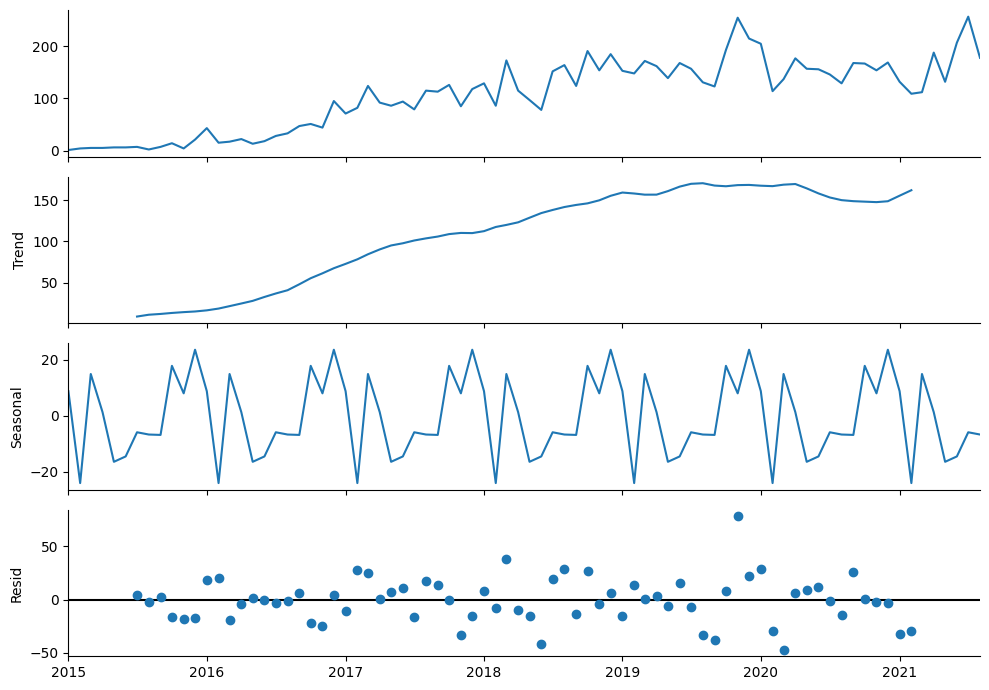

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7))
ts.plot(ax=axes[0], title="Titles added to Netflix per month")
axes[0].set_ylabel("Titles")
yearly = df.groupby("year_added").size()
yearly[yearly.index >= 2015].plot(kind="bar", ax=axes[1], color="#c44e52", rot=0, title="Titles added per year (2021 is partial: Jan–Sep)")
axes[1].set_ylabel("Titles")
plt.tight_layout()
plt.show()

decomp = seasonal_decompose(ts, model="additive", period=12)
fig = decomp.plot()
fig.set_size_inches(10, 7)
plt.tight_layout()
plt.show()

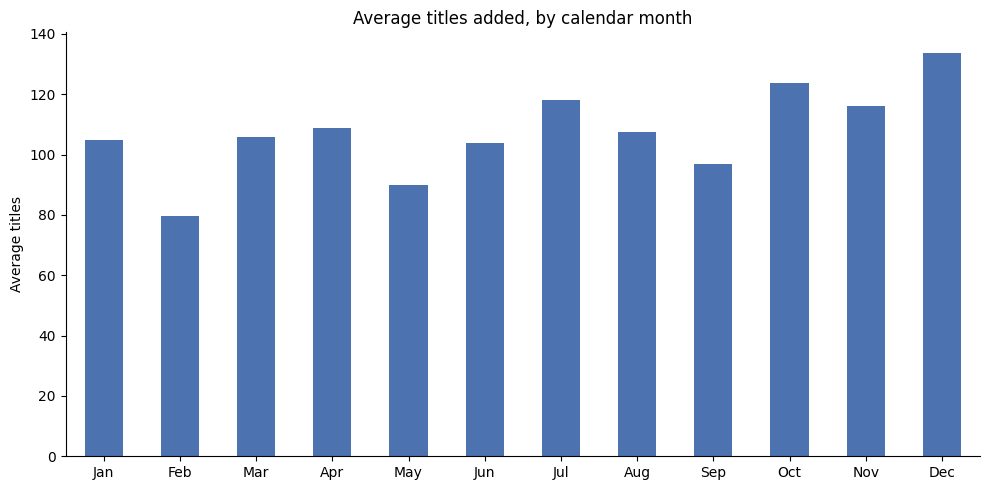

In [ ]:
# Which months are typically busiest?
by_month = ts.groupby(ts.index.month).mean().round(1)
by_month.index = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
by_month.plot(kind="bar", rot=0, color="#4c72b0", title="Average titles added, by calendar month")
plt.ylabel("Average titles")
plt.tight_layout()
plt.show()

## Step 3 – Build forecasting models

To judge a forecaster fairly I **hide the last 12 months** from the models, let them predict those months, and compare with what really happened. The three contenders:

1. **Seasonal naive (baseline):** "each month will be the same as the same month last year." Simple, but any serious model must beat it.
2. **Holt-Winters:** exponential smoothing that tracks a level, a trend and a yearly seasonal pattern, and puts more weight on recent months.
3. **SARIMA:** a classic statistical model that learns from past values and past errors, after removing trend and seasonality by differencing.

In [ ]:
TEST_MONTHS = 12
train, test = ts.iloc[:-TEST_MONTHS], ts.iloc[-TEST_MONTHS:]
print(f"Training months: {len(train)}   Test months: {len(test)}")

forecasts = {}

# 1) Seasonal naive
forecasts["Seasonal Naive"] = pd.Series(train.iloc[-12:].values, index=test.index)

# 2) Holt-Winters
hw = ExponentialSmoothing(train, trend="add", seasonal="add", seasonal_periods=12).fit()
forecasts["Holt-Winters"] = hw.forecast(TEST_MONTHS)

# 3) SARIMA
sarima = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
forecasts["SARIMA"] = sarima.get_forecast(TEST_MONTHS).predicted_mean

Training months: 68   Test months: 12


## Step 5 – Evaluate forecasting accuracy

- **MAE** (mean absolute error): on average, how many titles per month the forecast is off by.
- **RMSE** (root mean squared error): like MAE but punishes big misses harder.

Lower is better for both. Forecasts can't be negative, so I clip them at zero.

,MAE,RMSE
Seasonal Naive,47.33,57.06
Holt-Winters,35.45,42.88
SARIMA,48.72,55.68


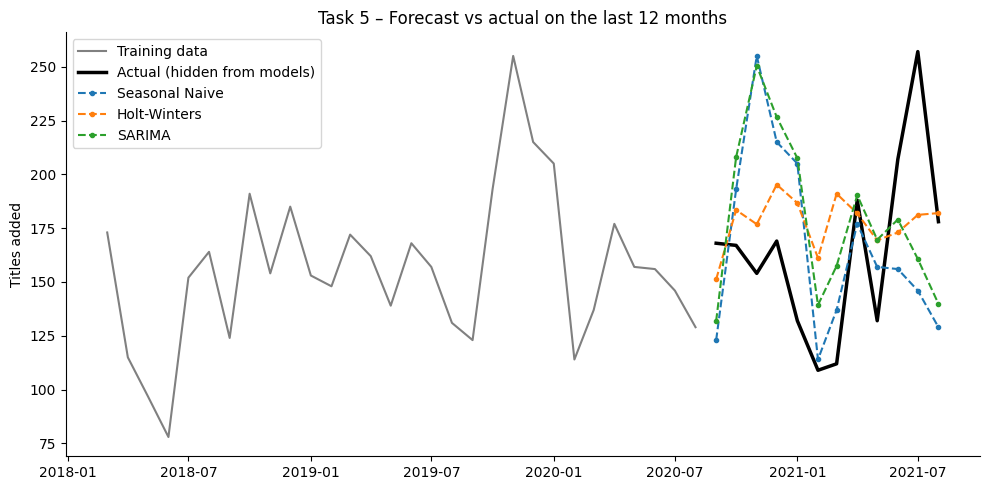

In [ ]:
rows = {}
for name, pred in forecasts.items():
    pred = pred.clip(lower=0)
    rows[name] = {"MAE": mean_absolute_error(test, pred),
                  "RMSE": np.sqrt(mean_squared_error(test, pred))}
results = pd.DataFrame(rows).T.round(2)
display(results)

plt.figure(figsize=(10, 5))
plt.plot(train.index[-30:], train.iloc[-30:], color="gray", label="Training data")
plt.plot(test.index, test, color="black", linewidth=2.5, label="Actual (hidden from models)")
for name, pred in forecasts.items():
    plt.plot(pred.index, pred.clip(lower=0), linestyle="--", marker="o", markersize=3, label=name)
plt.title("Task 5 – Forecast vs actual on the last 12 months")
plt.ylabel("Titles added")
plt.legend()
plt.tight_layout()
plt.show()

## Step 4 – Generate future predictions

I take the winner (lowest RMSE), refit it on **all** the data, so it also learns from the most recent year, and forecast the next 12 months.

Best model on the test period: Holt-Winters


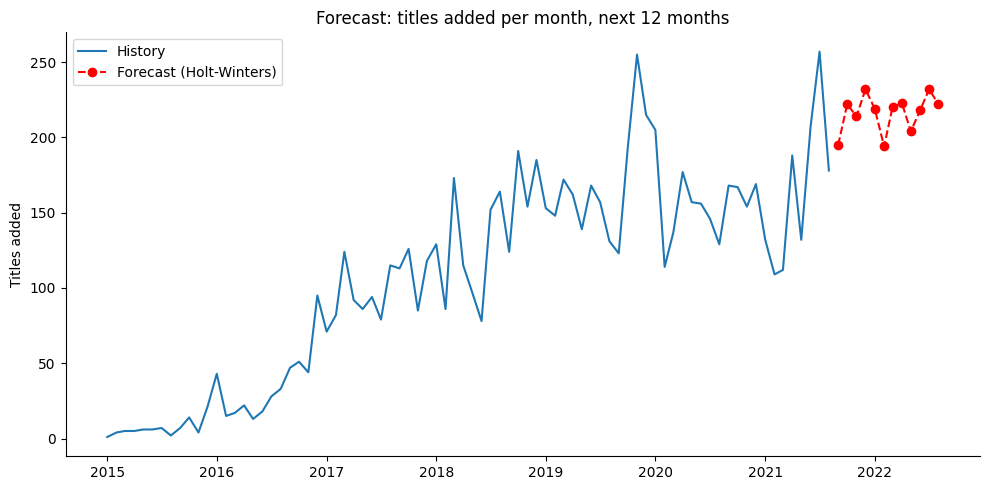

,forecast_titles
Sep 2021,195.0
Oct 2021,222.0
Nov 2021,214.0
Dec 2021,232.0
Jan 2022,219.0
Feb 2022,194.0
Mar 2022,220.0
Apr 2022,223.0
May 2022,204.0
Jun 2022,218.0


In [ ]:
best = results["RMSE"].idxmin()
print("Best model on the test period:", best)

if best == "Holt-Winters":
    final = ExponentialSmoothing(ts, trend="add", seasonal="add", seasonal_periods=12).fit()
    future = final.forecast(12)
elif best == "SARIMA":
    final = SARIMAX(ts, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    future = final.get_forecast(12).predicted_mean
else:
    idx = pd.date_range(ts.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
    future = pd.Series(ts.iloc[-12:].values, index=idx)

future = future.clip(lower=0).round()

plt.figure(figsize=(10, 5))
plt.plot(ts.index, ts, label="History")
plt.plot(future.index, future, color="red", linestyle="--", marker="o", label=f"Forecast ({best})")
plt.title("Forecast: titles added per month, next 12 months")
plt.ylabel("Titles added")
plt.legend()
plt.tight_layout()
plt.show()

forecast_table = future.to_frame("forecast_titles")
forecast_table.index = forecast_table.index.strftime("%b %Y")
forecast_table

## Conclusion

- The results table tells me whether the statistical models beat the "same as last year" baseline. If a model doesn't beat it, that is a legitimate finding and I should say so.
- The additions per month are noisy and the catalog changed a lot over the period (growth, then the 2020 pandemic disruption), so any forecast has wide uncertainty. Treat it as a *trend indication*, not a promise.
- **Limitations:** about 80 months is a short history for seasonal models, and the series reflects when Netflix *added* titles in this dataset, not the actual release schedule. Extra information (planned releases, holidays) would improve it.